# Phase 1- Setup and GitHub Basics

In [16]:
# WHY: Serves as a quick test and collaborative greeting to verify that every 
# team member has cloned the repo, can run Python in the notebook, and can push commits.

# Print greeting messages for each team member
print("Hello,Iris! - Harmanjot")
print("Hello,Iris! - Elshadie")
print("Hello,Iris! - Danawit")
print("Hello,Iris! - Olatunji")

Hello,Iris! - Harmanjot
Hello,Iris! - Elshadie
Hello,Iris! - Danawit
Hello,Iris! - Olatunji


# Phase 2- Python Fundamentals

In [17]:
# Variables
# WHY: Storing dataset attributes in variables allows us to reuse and reference data 
# properties clearly without hardcoding raw numbers directly into print statements.

# Assign basic dataset metadata (rows, columns, species count, and name) to variables
n_rows = 150
n_columns = 5
n_species = 3
dataset_name = "Iris"

# Print out the variable values neatly using labels
print("Dataset Name:", dataset_name)
print("Number Of Rows:", n_rows)
print("Number of Columns:", n_columns)
print("Number of Species:", n_species)

Dataset Name: Iris Dataset
Number Of Rows: 150
Number of Columns: 5
Number of Species: 3


In [18]:
# Control Structures 
# WHY: Conditional statements (if/else) enable programs to make decisions based on 
# specific numerical thresholds, forming the core logic for rule-based classification.

# Define sample numerical measurements for a flower
petal_length = 1.0
sepal_length = 6.3

# Evaluate petal size and print a label
if petal_length > 1.5:
    print("Large petal")
else: 
    print("Small petal")

# Evaluate sepal size against a threshold
if sepal_length > 5.0:
    print("Large sepal")
else: 
    print("Small sepal")

Small petal
Large sepal


In [31]:
# loops 
# WHY: Loops automate repetitive operations, allowing us to efficiently process 
# every element in a collection without writing separate print statements.

# Define a list containing the three distinct iris species names
species_list = ['Iris setosa', 'Iris versicolour', 'Iris virginica']

# Iterate through each item in the list sequentially and print it
for species in species_list:
    print(species)

Iris setosa
Iris versicolour
Iris virginica


In [20]:
# Functions 
# WHY: Functions organize logic into modular, reusable blocks so we can apply 
# the exact same classification rules to multiple inputs without rewriting code.

# Define a reusable function that classifies flowers based on sepal and petal lengths
def classify_flower(sepal_length, petal_length):
    if petal_length < 2.5 and sepal_length < 5.4:
        return "Small size flower"
    elif petal_length >= 5.0 and sepal_length >= 6.0:
        return "Large size flower"
    else:
        return "Medium size flower"

# Test the function with different sample measurements
print(classify_flower(6.2, 7.0))
print(classify_flower(1.2, 1.0))
print(classify_flower(4.0, 7.0))

Large size flower
Small size flower
Medium size flower


# Phase 3-File Handling & Data Cleaning

In [32]:
# WHY: Standardizing raw data files into a structured CSV format with proper column 
# headers ensures compatibility with standard data science libraries like Pandas.

import pandas as pd

# Define column headers for the raw UCI Iris dataset file
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

# Load the raw data file into a pandas DataFrame, assigning the defined column names
df = pd.read_csv('iris.data', header=None, names=column_names)

# Export the DataFrame into a standard CSV format for easier reading and processing
df.to_csv('iris.csv', index=False)

print("iris.csv has been successfully created!")

iris.csv has been successfully created!


In [22]:
# WHY: Using raw Python file handling (open(), csv.reader) demonstrates fundamental 
# file I/O operations and manual data aggregation without relying on high-level libraries.

import csv

input_file = 'iris.csv'
output_summary = 'summary.txt'

row_count = 0
sepal_lengths = []  # Empty list to hold numerical sepal length values

# Open and read the CSV file line by line
with open(input_file, mode='r') as file:
    csv_reader = csv.reader(file)
    header = next(csv_reader)  # Skip the header row

    for row in csv_reader:
        if row:  # Ensure the row is not empty
            row_count += 1 
            sepal_lengths.append(float(row[0]))  # Convert string to float and store

# Compute basic statistics using built-in Python functions
min_sepal = min(sepal_lengths)                    
max_sepal = max(sepal_lengths)                    
avg_sepal = sum(sepal_lengths) / len(sepal_lengths) 

# Write the aggregated summary results to a text file
with open(output_summary, mode='w') as summary_file:
    summary_file.write("--- Iris Dataset Summary ---\n")
    summary_file.write(f"Total Rows (excluding header): {row_count}\n")
    summary_file.write(f"Minimum Sepal Length: {min_sepal}\n")
    summary_file.write(f"Maximum Sepal Length: {max_sepal}\n")
    summary_file.write(f"Average Sepal Length: {avg_sepal:.2f}\n")

print("Success! 'summary.txt' has been created.")

Success! 'summary.txt' has been created.


In [23]:
# WHY: Real world datasets frequently contain missing values or duplicate records that 
# can skew analysis; inspecting and removing them ensures data integrity.

import pandas as pd

# Load the CSV file back into a pandas DataFrame
df = pd.read_csv('iris.csv')

# Inspect data types to ensure numbers are floats and text is string/object
print("Column Names & Data Types")
print(df.dtypes)

# Check for any missing/null values across all columns
print("\n Checking for Missing Values")
print(df.isnull().sum())

# Identify and count duplicate rows
print("\n  Handling Duplicate Rows")
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")

# Drop duplicate records to clean the dataset
df = df.drop_duplicates()
print(f"Rows remaining after dropping duplicates: {len(df)}")

# Save the verified and deduplicated dataset
df.to_csv('iris_cleaned.csv', index=False)
print("\nSuccess! Cleaned dataset saved as 'iris_cleaned.csv'.")

Column Names & Data Types
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

 Checking for Missing Values
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

  Handling Duplicate Rows
Duplicate rows found: 3
Rows remaining after dropping duplicates: 147

Success! Cleaned dataset saved as 'iris_cleaned.csv'.


# Phase 4-Analysis & Visualization

In [33]:
#  1. Count Flowers Manually Using a for Loop 

# WHY: Counting frequencies manually using loops and dictionaries builds algorithmic 
# thinking and reinforces how key-value data structures aggregate categories.

import pandas as pd

df = pd.read_csv('iris_cleaned.csv')
species_counts = {}

# Iterate through the species column and tally counts using a dictionary
for species in df['species']:
    if species in species_counts:
        species_counts[species] += 1
    else:
        species_counts[species] = 1

print("Flower Count per Species")
for species, count in species_counts.items():
    print(f"{species}: {count} flowers")

Flower Count per Species
Iris-setosa: 48 flowers
Iris-versicolor: 50 flowers
Iris-virginica: 49 flowers


In [25]:
#  2. Categorize Flowers Using If/Else & Save to CSV

# WHY: Turning raw numbers into simple groups (like short, medium, or long) 
# makes the data easier to read and gets it ready to be sorted into categories.

categories = []

# Categorize each flower based on its petal length using conditional checks
for petal_len in df['petal_length']:
    if petal_len < 2:
        categories.append("Short Petal")
    elif 2 <= petal_len <= 5:
        categories.append("Medium Petal")
    else:
        categories.append("Long Petal")

# Add the new category list as a column in the DataFrame and export
df['petal_category'] = categories
df.to_csv('iris_classes.csv', index=False)

print("Success! Categorized data saved to 'iris_classes.csv'.")
print(df[['petal_length', 'petal_category']].head(10))

Success! Categorized data saved to 'iris_classes.csv'.
   petal_length petal_category
0           1.4    Short Petal
1           1.4    Short Petal
2           1.3    Short Petal
3           1.5    Short Petal
4           1.4    Short Petal
5           1.7    Short Petal
6           1.4    Short Petal
7           1.5    Short Petal
8           1.4    Short Petal
9           1.5    Short Petal


In [26]:
# 3. Pandas Statistical Analysis

# WHY: Grouping data (groupby) allows us to compare subsets of the dataset independently, 
# uncovering key measurement differences between flower species.

# Compute overall statistical metrics (mean, median, min, max) for numerical columns
stats_summary = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].agg(['mean', 'median', 'min', 'max'])

print("Overall Statistics")
print(stats_summary)

# Group data by species to compute average measurements per flower type
species_averages = df.groupby('species').mean(numeric_only=True)

print("\nAverage Measurements by Species")
print(species_averages)

Overall Statistics
        sepal_length  sepal_width  petal_length  petal_width
mean        5.856463     3.055782      3.780272     1.208844
median      5.800000     3.000000      4.400000     1.300000
min         4.300000     2.000000      1.000000     0.100000
max         7.900000     4.400000      6.900000     2.500000

Average Measurements by Species
                 sepal_length  sepal_width  petal_length  petal_width
species                                                              
Iris-setosa          5.010417     3.431250      1.462500     0.250000
Iris-versicolor      5.936000     2.770000      4.260000     1.326000
Iris-virginica       6.604082     2.979592      5.561224     2.028571


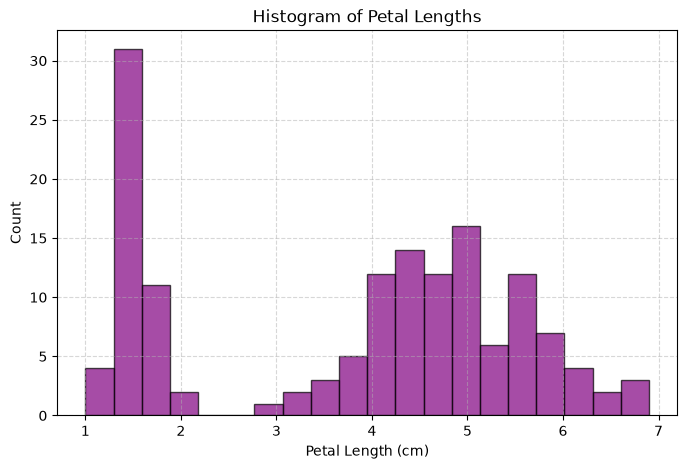

In [34]:
# 4.Data Visualizations (Plots & Charts)

# WHY: Visualizing data distributions with a histogram helps identify patterns, 
# skewness, or clusters (like separate species groups) that summary averages conceal.

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('iris_cleaned.csv')

plt.figure(figsize=(8, 5))
# Plot a histogram showing the distribution frequency of petal lengths
df['petal_length'].plot(
    kind='hist', 
    bins=20, 
    color='purple', 
    edgecolor='black', 
    alpha=0.7
)
plt.title('Histogram of Petal Lengths')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

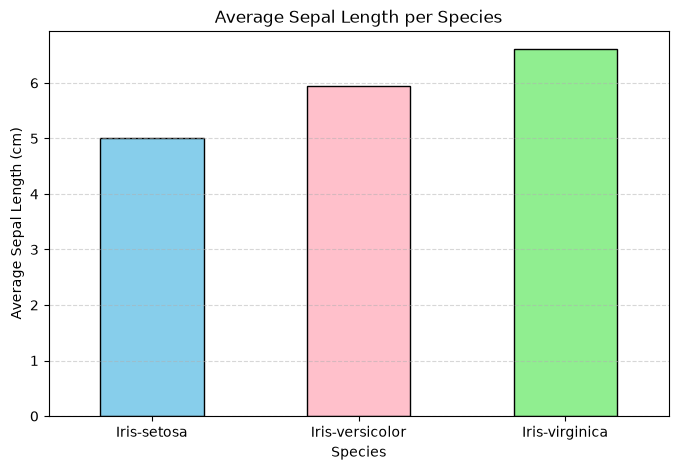

In [35]:
# WHY: Bar charts provide a clear, immediate visual comparison of average metric 
# values across discrete categories (species) for presentations and reports.

species_averages = df.groupby('species').mean()

plt.figure(figsize=(8, 5))
# Create a bar chart comparing average sepal length across species
species_averages['sepal_length'].plot(
    kind='bar', 
    color=['skyblue', 'pink', 'lightgreen'],
    edgecolor='black'
)
plt.title('Average Sepal Length per Species')
plt.xlabel('Species')
plt.ylabel('Average Sepal Length (cm)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

<Figure size 800x500 with 0 Axes>

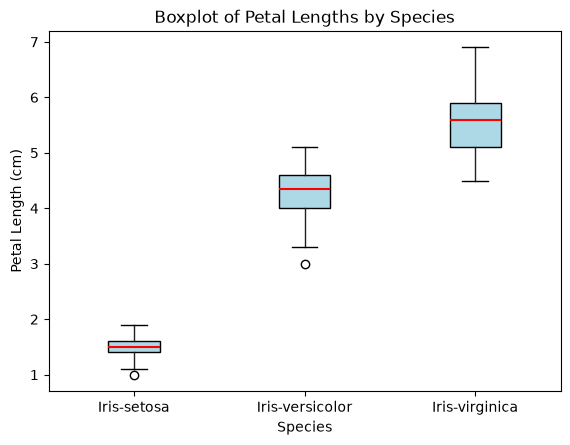

In [36]:
# WHY: Boxplots summarize data distribution spread (median, quartiles, and potential 
# outliers) compactly, making group-to-group comparisons straightforward.

plt.figure(figsize=(8, 5))

# Generate a boxplot to view data spread, medians, and outliers across species
df.boxplot(
    column='petal_length', 
    by='species', 
    grid=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='black'),
    medianprops=dict(color='red', linewidth=1.5)
)

plt.title('Boxplot of Petal Lengths by Species')
plt.suptitle('')  # Suppress default pandas multi-index suptitle
plt.xlabel('Species')
plt.ylabel('Petal Length (cm)')
plt.show()

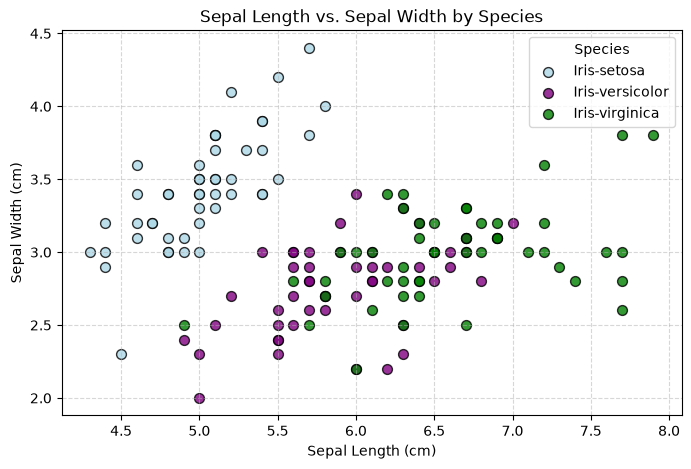

In [38]:
# WHY: Making a scatter plot lets us see if two measurements are related 
# (like checking if a longer sepal usually means a longer petal) by putting a dot for each flower.

plt.figure(figsize=(8, 5))

colors_dict = {'Iris-setosa': 'lightblue', 'Iris-versicolor': 'purple', 'Iris-virginica': 'green'}

# Iterate through each species group to plot points with distinct colors
for species, group in df.groupby('species'):
    plt.scatter(
        group['sepal_length'], 
        group['sepal_width'], 
        label=species, 
        alpha=0.8, 
        color=colors_dict.get(species, 'gray'),  # <-- This line applies your custom colors!
        edgecolors='black', 
        s=50
    )

plt.title('Sepal Length vs. Sepal Width by Species')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend(title='Species')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5.Answers to Analysis Questions

1).Which species has the smallest range of petal lengths?

    -Iris-setosa has the smallest range, with petal lengths tightly grouped around 1.0 to 1.9 cm.
<br>
2). Which species shows the largest spread in petal length values?

    -Iris-virginica and versicolor show the largest overall spread in petal length values.
<br>
3). How do the medians of the three species compare? What does this suggest about their flower sizes?

    -Setosa has the lowest median (~1.5 cm), Versicolor sits in the middle (~4.35 cm), and Virginica has the highest median (~5.55 cm). This demonstrates that Iris-setosa flowers are distinctly smaller in petal size compared to the other two species.
<br>
4). Do sepal length and sepal width appear strongly correlated? Explain why or why not using evidence from a scatter plot.

    -No, they are not strongly correlated overall. On the scatter plot, the data points do not form a single linear pattern across all species.
<br>
5). Based on the scatter, boxplot, and histogram, which flower features seem most useful for separating the species?

    -Petal length and petal width are the most useful features because their boxplots and distributions show clear, distinct separation with minimal overlap between species.

In [3]:
import pandas as pd

import numpy as np
 
# Load your cleaned dataset

df_clean = pd.read_csv("iris_cleaned.csv")

features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
 
print(f"Initial dataset shape: {df_clean.shape}")
 
# 1. Check for exact duplicate rows

duplicate_count = df_clean.duplicated().sum()

print(f"\n--- 1. Duplicate Rows Found: {duplicate_count} ---")

if duplicate_count > 0:

    print(df_clean[df_clean.duplicated(keep=False)])
 
# 2. Check for invalid/impossible measurements (<= 0 cm)

invalid_rows = df_clean[(df_clean[features] <= 0).any(axis=1)]

print(f"\n--- 2. Invalid (<= 0) Rows Found: {len(invalid_rows)} ---")
 
# 3. Detect outliers using the IQR (Interquartile Range) method

print("\n--- 3. Outlier Detection (IQR Method) ---")

outlier_indices = set()
 
for col in features:

    Q1 = df_clean[col].quantile(0.25)

    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    col_outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]

    outlier_indices.update(col_outliers.index)

    print(f"{col}: {len(col_outliers)} outliers (Valid range: {lower_bound:.2f} to {upper_bound:.2f} cm)")
 
print(f"Total unique rows flagged as outliers: {len(outlier_indices)}")
 

Initial dataset shape: (147, 5)

--- 1. Duplicate Rows Found: 0 ---

--- 2. Invalid (<= 0) Rows Found: 0 ---

--- 3. Outlier Detection (IQR Method) ---
sepal_length: 0 outliers (Valid range: 3.15 to 8.35 cm)
sepal_width: 4 outliers (Valid range: 2.05 to 4.05 cm)
petal_length: 0 outliers (Valid range: -3.65 to 10.35 cm)
petal_width: 0 outliers (Valid range: -1.95 to 4.05 cm)
Total unique rows flagged as outliers: 4


In [8]:
# 1. Remove exact duplicates (keeps the first occurrence)
df_ready = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df_ready.shape}")
 
# 2. Handle Outliers (Choose Option A OR Option B)
 
# Cap extreme values at the IQR fences
# This preserves all 147 unique flowers while preventing extreme values from skewing KNN/Logistic Regression
for col in features:
    Q1 = df_ready[col].quantile(0.25)
    Q3 = df_ready[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_ready[col] = df_ready[col].clip(lower=lower_bound, upper=upper_bound)
 
# 3. Verify final class balance and save the model-ready file
print("\n--- Final Class Distribution ---")
print(df_ready["species"].value_counts())
 
df_ready.to_csv("iris_model_ready.csv", index=False)
print("\nSaved 'iris_model_ready.csv' — ready for train_test_split!")

Shape after removing duplicates: (147, 5)

--- Final Class Distribution ---
species
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64

Saved 'iris_model_ready.csv' — ready for train_test_split!


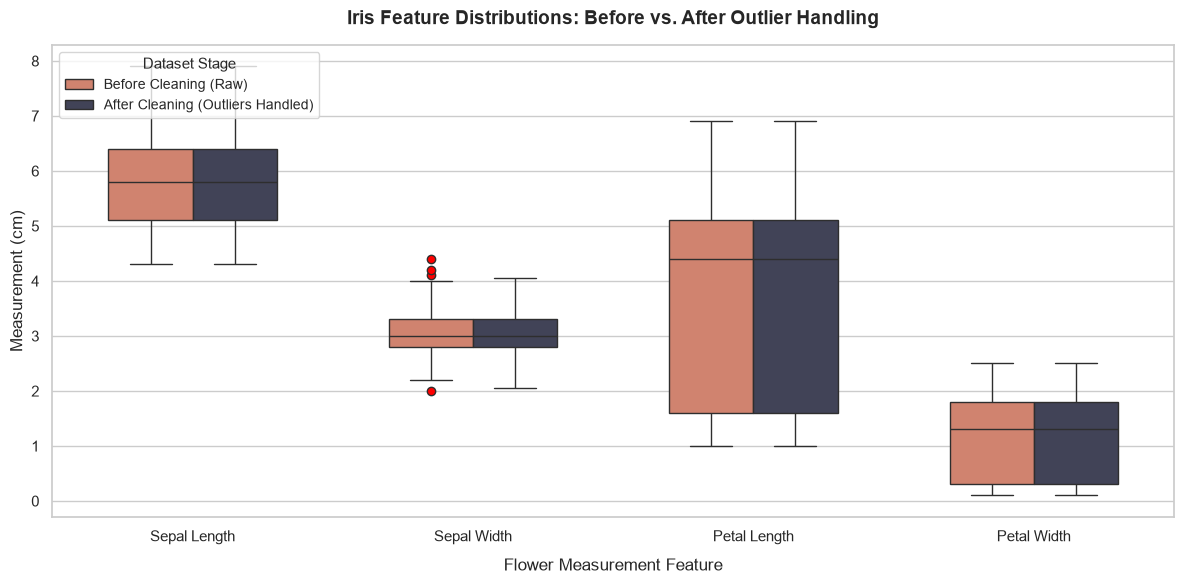

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
# Ensure clean light styling for your report figure
plt.style.use("default")
sns.set_theme(style="whitegrid")
 
# Load both versions of your dataset
df_before = pd.read_csv("iris_cleaned.csv")
df_after = pd.read_csv("iris_model_ready.csv")
 
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
 
# Reshape both DataFrames from wide to long format for side-by-side plotting
before_melted = df_before[features].melt(var_name="Feature", value_name="Centimeters")
before_melted["Stage"] = "Before Cleaning (Raw)"
 
after_melted = df_after[features].melt(var_name="Feature", value_name="Centimeters")
after_melted["Stage"] = "After Cleaning (Outliers Handled)"
 
df_compare = pd.concat([before_melted, after_melted], ignore_index=True)
 
# Create the side-by-side boxplot figure
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=df_compare,
    x="Feature",
    y="Centimeters",
    hue="Stage",
    palette=["#E07A5F", "#3D405B"],
    width=0.6,
    flierprops={"marker": "o", "markersize": 6, "markerfacecolor": "red"}
)
 
# Customize titles and labels
plt.title("Iris Feature Distributions: Before vs. After Outlier Handling", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Flower Measurement Feature", fontsize=12, labelpad=10)
plt.ylabel("Measurement (cm)", fontsize=12)
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=["Sepal Length", "Sepal Width", "Petal Length", "Petal Width"],
    fontsize=11
)
plt.legend(title="Dataset Stage", fontsize=10, title_fontsize=11, loc="upper left")
 
plt.tight_layout()
plt.savefig("iris_outlier_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
 
# 1. Load your cleaned dataset
df_model = pd.read_csv("iris_model_ready.csv")
 
# Separate features (X) and target species (y)
X = df_model[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = df_model["species"]
 
# 2. Split into 80% training and 20% testing sets (stratified to keep species balanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
 
# 3. Initialize the three models
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "K-Nearest Neighbors (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42)
}
 
# 4. Train, predict, and evaluate each model
print("--- Model Accuracy Comparison ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}: {acc:.2%}")
 
# 5. Detailed breakdown for the Decision Tree (or swap in any model from `models`)
dt_model = models["Decision Tree"]
dt_preds = dt_model.predict(X_test)
 
print("\n--- Decision Tree Classification Report ---")
print(classification_report(y_test, dt_preds))
 
print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, dt_preds))

--- Model Accuracy Comparison ---
Logistic Regression: 93.33%
K-Nearest Neighbors (k=5): 93.33%
Decision Tree: 96.67%

--- Decision Tree Classification Report ---
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

--- Confusion Matrix ---
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


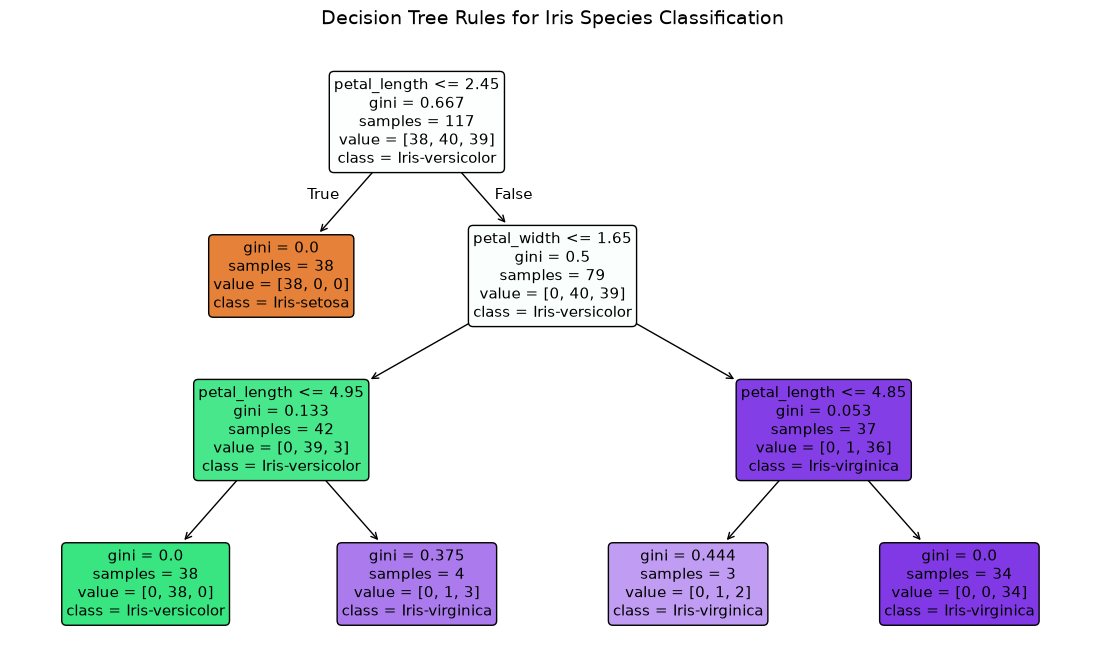

--- Text Representation of Decision Tree Rules ---
|--- petal_length <= 2.45
|   |--- class: Iris-setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.65
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: Iris-versicolor
|   |   |--- petal_length >  4.95
|   |   |   |--- class: Iris-virginica
|   |--- petal_width >  1.65
|   |   |--- petal_length <= 4.85
|   |   |   |--- class: Iris-virginica
|   |   |--- petal_length >  4.85
|   |   |   |--- class: Iris-virginica



In [13]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text
 
# Reset plot style to default light background so tree text is crisp and readable
plt.style.use("default")
 
# 1. Plot the visual Decision Tree diagram
plt.figure(figsize=(14, 8))
plot_tree(
    dt_model,
    feature_names=["sepal_length", "sepal_width", "petal_length", "petal_width"],
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Rules for Iris Species Classification", fontsize=14, pad=15)
plt.savefig("iris_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()
 
# 2. Print text-based IF/ELSE rules for easy reading
print("--- Text Representation of Decision Tree Rules ---")
tree_rules = export_text(
    dt_model,
    feature_names=["sepal_length", "sepal_width", "petal_length", "petal_width"]
)
print(tree_rules)

C:\Users\hkaur\anaconda3\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
C:\Users\hkaur\anaconda3\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


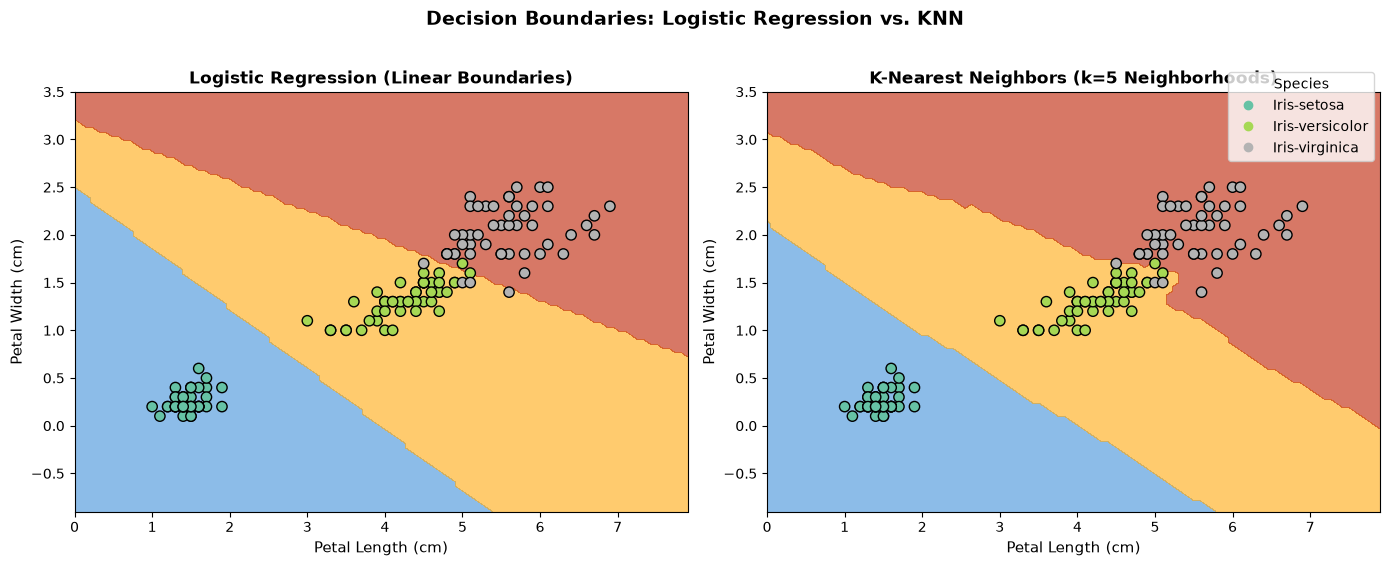

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
 
plt.style.use("default")
 
# Load the deduplicated, outlier-handled dataset
df_ready = pd.read_csv("iris_model_ready.csv")
 
# Use the two strongest predictors so we can plot in 2D
X_2d = df_ready[["petal_length", "petal_width"]]
le = LabelEncoder()
y_encoded = le.fit_transform(df_ready["species"])
 
# Define the two pipelines
models_2d = {
    "Logistic Regression (Linear Boundaries)": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "K-Nearest Neighbors (k=5 Neighborhoods)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
 
for ax, (title, clf) in zip(axes, models_2d.items()):
    clf.fit(X_2d, y_encoded)
    # Plot the colored decision regions
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X_2d,
        cmap=plt.cm.Set2,
        response_method="predict",
        ax=ax,
        alpha=0.6
    )
    # Overlay the actual flower measurements
    scatter = ax.scatter(
        X_2d["petal_length"],
        X_2d["petal_width"],
        c=y_encoded,
        cmap=plt.cm.Set2,
        edgecolor="black",
        s=55
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Petal Length (cm)", fontsize=11)
    ax.set_ylabel("Petal Width (cm)", fontsize=11)
 
# Add a shared legend for the three species
handles, _ = scatter.legend_elements()
fig.legend(handles, le.classes_, title="Species", loc="upper right", bbox_to_anchor=(0.99, 0.92))
 
plt.suptitle("Decision Boundaries: Logistic Regression vs. KNN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("iris_knn_logreg_boundaries.png", dpi=300, bbox_inches="tight")
plt.show()

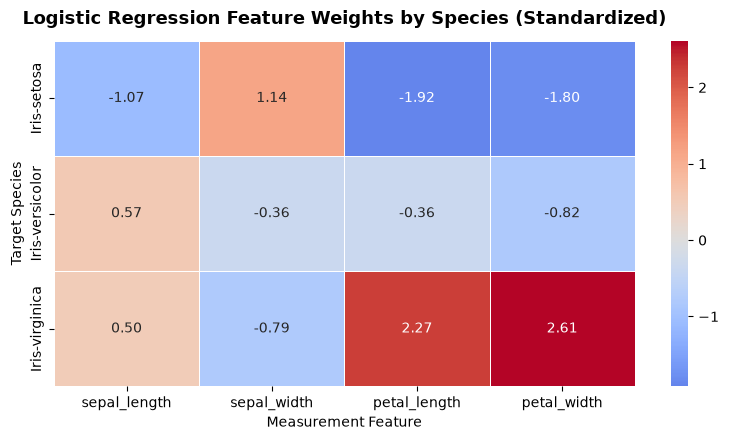

In [17]:
import seaborn as sns
 
# Train full 4-feature Logistic Regression on iris_model_ready.csv
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X_full = df_ready[features]
y_full = df_ready["species"]
 
logreg_pipe = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
logreg_pipe.fit(X_full, y_full)
 
# Extract learned weights for each species
clf_lr = logreg_pipe.named_steps["logisticregression"]
coef_df = pd.DataFrame(clf_lr.coef_, columns=features, index=clf_lr.classes_)
 
# Plot heatmap of feature weights
plt.figure(figsize=(8, 4.5))
sns.heatmap(coef_df, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Logistic Regression Feature Weights by Species (Standardized)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Measurement Feature")
plt.ylabel("Target Species")
plt.tight_layout()
plt.savefig("iris_logreg_weights.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier
 
# 1. Load your deduplicated, outlier-handled dataset

df_ready = pd.read_csv("iris_model_ready.csv")

X = df_ready[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

y = df_ready["species"]
 
# 2. Define 5-fold stratified cross-validation (keeps class proportions balanced in every fold)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
# 3. Your three models (scaling stays inside each pipeline to prevent data leakage)

three_models = {

    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),

    "K-Nearest Neighbors (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),

    "Decision Tree (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42)

}
 
# 4. Evaluate and print fold-by-fold + mean accuracy

print("--- 5-Fold Cross-Validation Results (All 147 Samples) ---")

for name, model in three_models.items():

    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

    fold_str = ", ".join([f"{s:.2%}" for s in scores])

    print(f"\n{name}:")

    print(f"  Fold Scores : [{fold_str}]")

    print(f"  Mean Accuracy: {scores.mean():.2%} (+/- {scores.std():.2%})")
 

--- 5-Fold Cross-Validation Results (All 147 Samples) ---

Logistic Regression:
  Fold Scores : [100.00%, 96.67%, 96.55%, 93.10%, 93.10%]
  Mean Accuracy: 95.89% (+/- 2.59%)

K-Nearest Neighbors (k=5):
  Fold Scores : [100.00%, 93.33%, 96.55%, 96.55%, 93.10%]
  Mean Accuracy: 95.91% (+/- 2.53%)

Decision Tree (max_depth=3):
  Fold Scores : [93.33%, 96.67%, 96.55%, 93.10%, 86.21%]
  Mean Accuracy: 93.17% (+/- 3.80%)


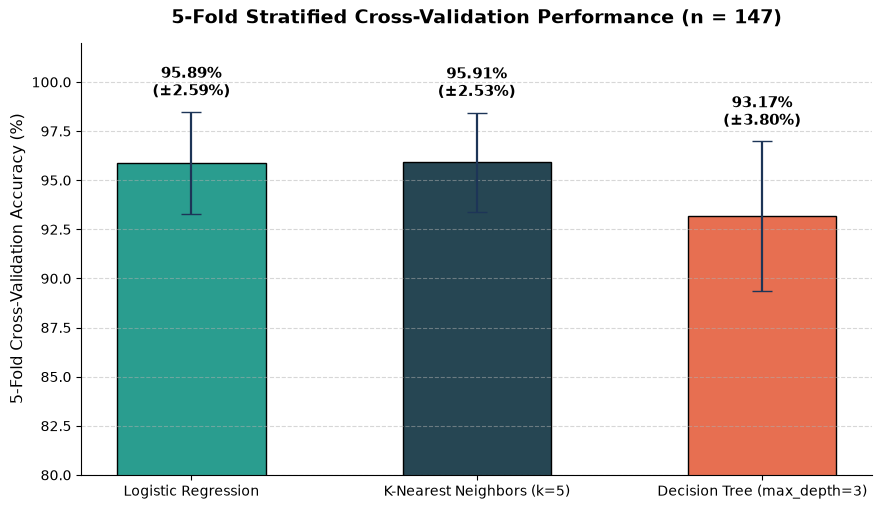

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
 
plt.style.use("default")
 
# Compute 5-fold CV mean and std using the exact models & cv from Cell 56
cv_summary = []
for name, model in three_models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_summary.append({
        "Model": name,
        "Mean Accuracy": scores.mean() * 100,
        "Std Dev": scores.std() * 100
    })
 
cv_df = pd.DataFrame(cv_summary)
 
# Plot bar chart with standard deviation error bars
fig, ax = plt.subplots(figsize=(9, 5.2))
colors = ["#2A9D8F", "#264653", "#E76F51"]
 
bars = ax.bar(
    cv_df["Model"],
    cv_df["Mean Accuracy"],
    yerr=cv_df["Std Dev"],
    capsize=7,
    color=colors,
    edgecolor="black",
    width=0.52,
    error_kw={"elinewidth": 1.6, "ecolor": "#1D3557"}
)
 
# Add exact value labels above each bar
for bar, (_, row) in zip(bars, cv_df.iterrows()):
    y_pos = row["Mean Accuracy"] + row["Std Dev"] + 0.6
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        y_pos,
        f"{row['Mean Accuracy']:.2f}%\n(±{row['Std Dev']:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10.5,
        fontweight="bold"
    )
 
ax.set_ylim(80, 102)
ax.set_ylabel("5-Fold Cross-Validation Accuracy (%)", fontsize=11.5)
ax.set_title("5-Fold Stratified Cross-Validation Performance (n = 147)", fontsize=13.5, fontweight="bold", pad=14)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
 
plt.tight_layout()
plt.savefig("iris_5fold_cv_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Optimal k = 13 -> Mean 5-Fold Accuracy: 97.26% (±1.37%)


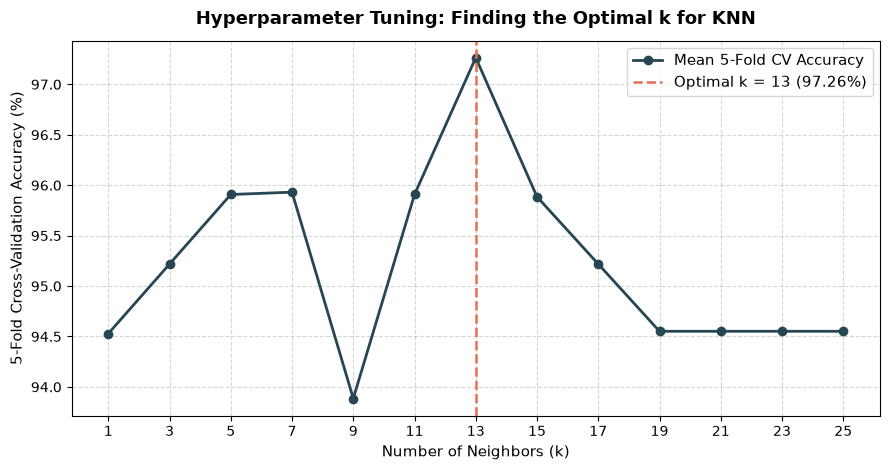

In [22]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
 
plt.style.use("default")
 
# 1. Load your deduplicated, outlier-handled dataset

df_ready = pd.read_csv("iris_model_ready.csv")

X = df_ready[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

y = df_ready["species"]
 
# 2. Test odd values of k from 1 to 25 using 5-fold Stratified Cross-Validation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_values = list(range(1, 26, 2))

mean_scores = []

std_scores = []
 
for k in k_values:

    knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

    scores = cross_val_score(knn_pipe, X, y, cv=cv, scoring="accuracy")

    mean_scores.append(scores.mean() * 100)

    std_scores.append(scores.std() * 100)
 
# 3. Identify the best k (highest mean accuracy, tie-broken by lowest std dev)

results_df = pd.DataFrame({"k": k_values, "Mean_Acc": mean_scores, "Std_Dev": std_scores})

best_row = results_df.sort_values(by=["Mean_Acc", "Std_Dev"], ascending=[False, True]).iloc[0]

best_k = int(best_row["k"])
 
print(f"Optimal k = {best_k} -> Mean 5-Fold Accuracy: {best_row['Mean_Acc']:.2f}% (±{best_row['Std_Dev']:.2f}%)")
 
# 4. Plot Accuracy vs. k

plt.figure(figsize=(9, 4.8))

plt.plot(k_values, mean_scores, marker="o", linewidth=2, color="#264653", label="Mean 5-Fold CV Accuracy")

plt.axvline(best_k, color="#E76F51", linestyle="--", linewidth=1.8, label=f"Optimal k = {best_k} ({best_row['Mean_Acc']:.2f}%)")
 
plt.xticks(k_values)

plt.xlabel("Number of Neighbors (k)", fontsize=11)

plt.ylabel("5-Fold Cross-Validation Accuracy (%)", fontsize=11)

plt.title("Hyperparameter Tuning: Finding the Optimal k for KNN", fontsize=13, fontweight="bold", pad=12)

plt.grid(True, linestyle="--", alpha=0.5)

plt.legend(fontsize=10.5)

plt.tight_layout()

plt.savefig("iris_knn_optimal_k.png", dpi=300, bbox_inches="tight")

plt.show()

In [23]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier
 
# Load deduplicated, outlier-capped dataset

df_ready = pd.read_csv("iris_model_ready.csv")

X = df_ready[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

y = df_ready["species"]
 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
# Final model comparison with Tuned KNN (k=13)

final_models = {

    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),

    "KNN (k=5 Baseline)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),

    "KNN (k=13 Tuned)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=13)),

    "Decision Tree (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42)

}
 
print("--- Final 5-Fold Stratified Cross-Validation Summary (n = 147) ---")

summary_rows = []

for name, model in final_models.items():

    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

    summary_rows.append({

        "Model": name,

        "Mean Accuracy": f"{scores.mean():.2%}",

        "Std Dev (±)": f"±{scores.std():.2%}",

        "Min Fold": f"{scores.min():.2%}",

        "Max Fold": f"{scores.max():.2%}"

    })
 
print(pd.DataFrame(summary_rows).to_string(index=False))
 

--- Final 5-Fold Stratified Cross-Validation Summary (n = 147) ---
                      Model Mean Accuracy Std Dev (±) Min Fold Max Fold
        Logistic Regression        95.89%      ±2.59%   93.10%  100.00%
         KNN (k=5 Baseline)        95.91%      ±2.53%   93.10%  100.00%
           KNN (k=13 Tuned)        97.26%      ±1.37%   96.55%  100.00%
Decision Tree (max_depth=3)        93.17%      ±3.80%   86.21%   96.67%
